
PERCEPTRON AND MULTI-LAYER PERCEPTRON ARCHITECTURAL BLUEPRINT
Using Iris and Handwritten Digits Datasets

EXPERIMENT 1: PERCEPTRON ON IRIS (SETOSA VS THE REST)
Epoch   1 | Misclassified: 1
Epoch   2 | Misclassified: 0
Converged at epoch 2
Weights = [-0.002  0.025 -0.068 -0.058], Bias = -0.100
Train Accuracy: 100.0%
Validation Accuracy: 100.0%
Test Accuracy: 100.0%

Perceptron on Versicolor vs Virginica
Converged at epoch 7
Best-effort test accuracy: 92.9%
Final epoch errors: 0

EXPERIMENT 2: MLP ON IRIS (3 CLASSES, SOFTMAX)
Gradient check relative error: 3.10e-10
Epoch    1 | LR 0.1000 | Train Loss 0.5561 | Train Accuracy 79.6% | Validation Loss 0.5376 | Validation Accuracy 85.7%
Epoch   40 | LR 0.1000 | Train Loss 0.0110 | Train Accuracy 100.0% | Validation Loss 0.4257 | Validation Accuracy 90.5%
Epoch   80 | LR 0.1000 | Train Loss 0.0060 | Train Accuracy 100.0% | Validation Loss 0.5820 | Validation Accuracy 90.5%
Epoch  120 | LR 0.1000 | Train Loss 0.0056 | Train Accuracy 100.0% | V

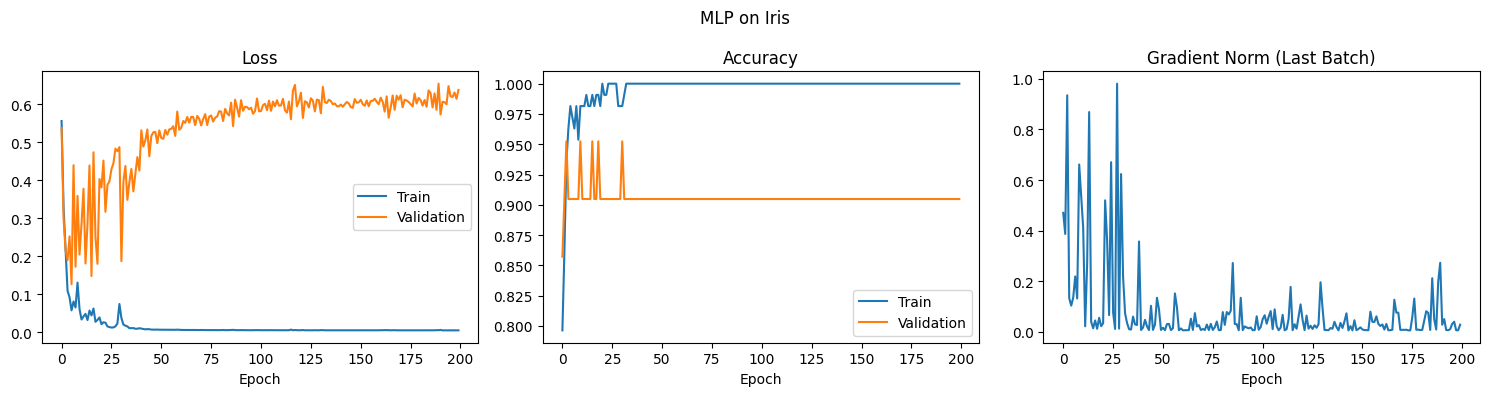

Saved iris_training.png

EXPERIMENT 3: MLP ON DIGITS (8x8 IMAGES, 10 CLASSES)
Train shape: (1265, 64)
Validation shape: (266, 64)
Test shape: (266, 64)
Gradient check relative error: 2.23e-09
Epoch    1 | LR 0.0495 | Train Loss 0.2035 | Train Accuracy 93.3% | Validation Loss 0.2894 | Validation Accuracy 92.5%
Epoch   10 | LR 0.0455 | Train Loss 0.0017 | Train Accuracy 100.0% | Validation Loss 0.2996 | Validation Accuracy 95.1%
Epoch   20 | LR 0.0417 | Train Loss 0.0008 | Train Accuracy 100.0% | Validation Loss 0.3084 | Validation Accuracy 95.5%
Early stopping at epoch 21

TEST Accuracy: 96.99%
Confusion Matrix:
 [[26  0  0  0  0  0  0  0  0  0]
 [ 0 27  0  0  0  0  0  0  0  0]
 [ 0  0 26  0  0  0  0  0  0  0]
 [ 0  0  0 24  0  2  0  0  1  0]
 [ 0  0  0  0 27  0  0  0  0  0]
 [ 0  0  0  0  0 27  0  0  0  0]
 [ 0  0  0  1  0  0 26  0  0  0]
 [ 0  0  0  0  0  0  0 25  0  1]
 [ 0  1  0  0  0  0  0  0 24  1]
 [ 0  0  0  0  0  1  0  0  0 26]]
       class  precision   recall       f1  suppor

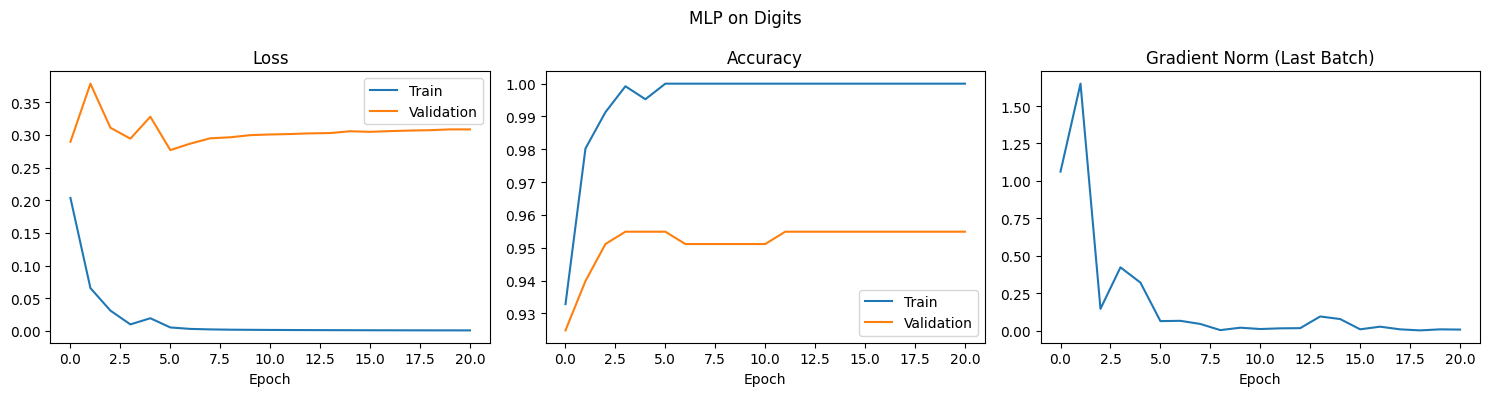

Saved digits_training.png


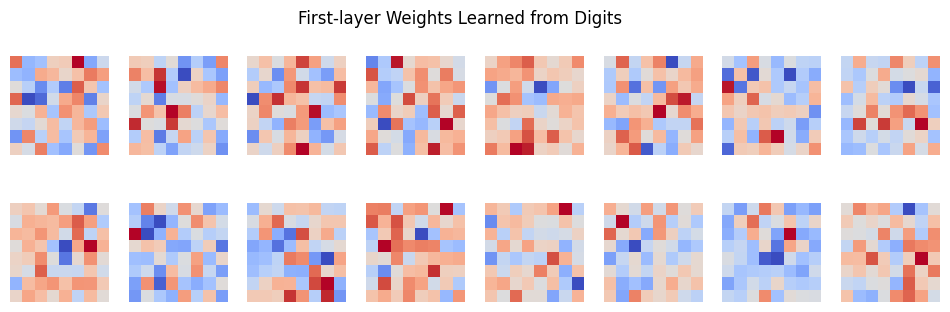

Saved digits_weights.png

EXPERIMENT 4: EFFECT OF LEARNING RATE AND ACTIVATION (DIGITS, 30 EPOCHS)
 Activation      LR  Final Val Loss Test Accuracy
       relu   0.001          0.3211        95.49%
       relu   0.010          0.2024        96.99%
       relu   0.100          0.4001        96.99%
       tanh   0.001          0.3428        95.86%
       tanh   0.010          0.1281        96.62%
       tanh   0.100          0.1822        96.99%
    sigmoid   0.001          1.1461        86.47%
    sigmoid   0.010          0.2092        96.62%
    sigmoid   0.100          0.1264        96.62%
 leaky_relu   0.001          0.3203        95.49%
 leaky_relu   0.010          0.2128        96.99%
 leaky_relu   0.100          0.3264        96.99%

ALL EXPERIMENTS COMPLETED SUCCESSFULLY!


In [1]:
"""
PERCEPTRON AND MULTI-LAYER PERCEPTRON ARCHITECTURAL BLUEPRINT
=============================================================

Datasets:
1. Iris Dataset - 150 samples, 4 features, 3 classes.
2. Digits Dataset - 1797 samples, 8x8 images, 10 classes.

Implementation:
- Perceptron from scratch using NumPy.
- Multi-Layer Perceptron from scratch using NumPy.
- Forward propagation.
- Backpropagation.
- Activation functions.
- Gradient descent.
- Momentum optimization.
- L2 regularization.
- Early stopping.
- Model evaluation and visualization.

Run this program in Google Colab.
"""

# ============================================================
# 1. IMPORTING REQUIRED LIBRARIES
# ============================================================

import numpy as np
from sklearn.datasets import load_iris, load_digits

SEED = 42
np.random.seed(SEED)


# ============================================================
# 2. DATA UTILITIES
# ============================================================

def train_val_test_split(X, y, val=0.15, test=0.15, seed=SEED):

    """Stratified train, validation and test split."""

    rng = np.random.RandomState(seed)

    tr_idx, va_idx, te_idx = [], [], []

    for c in np.unique(y):

        idx = rng.permutation(np.where(y == c)[0])

        n = len(idx)

        n_te = int(n * test)
        n_va = int(n * val)

        te_idx += list(idx[:n_te])
        va_idx += list(idx[n_te:n_te + n_va])
        tr_idx += list(idx[n_te + n_va:])

    tr_idx, va_idx, te_idx = map(
        lambda a: rng.permutation(a),
        (tr_idx, va_idx, te_idx)
    )

    return (
        X[tr_idx], y[tr_idx],
        X[va_idx], y[va_idx],
        X[te_idx], y[te_idx]
    )


# ============================================================
# 3. STANDARD SCALER
# ============================================================

class StandardScaler:

    def fit(self, X):

        self.mean = X.mean(axis=0)
        self.std = X.std(axis=0)

        self.std[self.std == 0] = 1.0

        return self

    def transform(self, X):

        return (X - self.mean) / self.std


# ============================================================
# 4. ONE HOT ENCODING
# ============================================================

def one_hot(y, n_classes):

    out = np.zeros((len(y), n_classes))

    out[np.arange(len(y)), y] = 1.0

    return out


# ============================================================
# 5. CONFUSION MATRIX
# ============================================================

def confusion_matrix(y_true, y_pred, n_classes):

    cm = np.zeros((n_classes, n_classes), dtype=int)

    for t, p in zip(y_true, y_pred):

        cm[t, p] += 1

    return cm


# ============================================================
# 6. CLASSIFICATION REPORT
# ============================================================

def classification_report(cm, names=None):

    n = cm.shape[0]

    names = names or [str(i) for i in range(n)]

    print(
        f"{'class':>12} {'precision':>10} "
        f"{'recall':>8} {'f1':>8} {'support':>8}"
    )

    for i in range(n):

        tp = cm[i, i]

        fp = cm[:, i].sum() - tp

        fn = cm[i, :].sum() - tp

        prec = tp / (tp + fp) if tp + fp else 0.0

        rec = tp / (tp + fn) if tp + fn else 0.0

        f1 = (
            2 * prec * rec / (prec + rec)
            if prec + rec else 0.0
        )

        print(
            f"{names[i]:>12} {prec:10.3f} "
            f"{rec:8.3f} {f1:8.3f} {cm[i].sum():8d}"
        )

    print(
        f"{'accuracy':>12} "
        f"{np.trace(cm) / cm.sum():28.3f} "
        f"{cm.sum():8d}"
    )


# ============================================================
# 7. SINGLE LAYER PERCEPTRON
# ============================================================

class Perceptron:

    """
    Rosenblatt Perceptron.

    z = x.w + b

    Prediction:
    y_hat = 1 if z >= 0 else 0

    Weight update:
    w = w + learning_rate * (y - y_hat) * x
    """

    def __init__(self, n_features, lr=0.1, seed=SEED):

        rng = np.random.RandomState(seed)

        self.w = rng.randn(n_features) * 0.01

        self.b = 0.0

        self.lr = lr

        self.errors_per_epoch = []

    def predict(self, X):

        return (
            X @ self.w + self.b >= 0
        ).astype(int)

    def fit(self, X, y, epochs=100, verbose=True):

        for ep in range(1, epochs + 1):

            order = np.random.permutation(len(X))

            errors = 0

            for i in order:

                y_hat = int(
                    X[i] @ self.w + self.b >= 0
                )

                delta = y[i] - y_hat

                if delta != 0:

                    self.w += self.lr * delta * X[i]

                    self.b += self.lr * delta

                    errors += 1

            self.errors_per_epoch.append(errors)

            if verbose and (
                ep == 1 or ep % 5 == 0 or errors == 0
            ):

                print(
                    f"Epoch {ep:3d} | "
                    f"Misclassified: {errors}"
                )

            if errors == 0:

                print(f"Converged at epoch {ep}")

                break

        return self


# ============================================================
# 8. ACTIVATION FUNCTIONS
# ============================================================

class Act:

    @staticmethod
    def relu(z):

        return np.maximum(0.0, z)

    @staticmethod
    def relu_d(z, a):

        return (z > 0).astype(z.dtype)

    @staticmethod
    def tanh(z):

        return np.tanh(z)

    @staticmethod
    def tanh_d(z, a):

        return 1.0 - a ** 2

    @staticmethod
    def sigmoid(z):

        return 1.0 / (
            1.0 + np.exp(-np.clip(z, -500, 500))
        )

    @staticmethod
    def sigmoid_d(z, a):

        return a * (1.0 - a)

    @staticmethod
    def leaky(z, alpha=0.01):

        return np.where(z > 0, z, alpha * z)

    @staticmethod
    def leaky_d(z, a, alpha=0.01):

        return np.where(z > 0, 1.0, alpha)


# ============================================================
# 9. ACTIVATION FUNCTION DICTIONARY
# ============================================================

ACTIVATIONS = {

    "relu": (Act.relu, Act.relu_d),

    "tanh": (Act.tanh, Act.tanh_d),

    "sigmoid": (Act.sigmoid, Act.sigmoid_d),

    "leaky_relu": (Act.leaky, Act.leaky_d)

}


# ============================================================
# 10. SOFTMAX FUNCTION
# ============================================================

def softmax(z):

    z = z - z.max(axis=1, keepdims=True)

    e = np.exp(z)

    return e / e.sum(axis=1, keepdims=True)


# ============================================================
# 11. CROSS ENTROPY LOSS
# ============================================================

def cross_entropy(probs, Y_onehot, eps=1e-12):

    return -np.mean(
        np.sum(
            Y_onehot * np.log(
                np.clip(probs, eps, 1.0)
            ),
            axis=1
        )
    )


# ============================================================
# 12. MULTI-LAYER PERCEPTRON
# ============================================================

class MLP:

    """
    Fully connected neural network for multi-class classification.

    Forward propagation:
        Z = A_previous @ W + b
        A = Activation(Z)

    Output layer:
        Softmax

    Loss:
        Categorical cross entropy + L2 regularization

    Backpropagation:
        Calculates gradients using the chain rule.

    Optimizer:
        Gradient descent with optional momentum.
    """

    def __init__(
        self,
        sizes,
        hidden="relu",
        lr=0.1,
        l2=0.0,
        momentum=0.0,
        lr_decay=0.0,
        seed=SEED
    ):

        self.sizes = sizes

        self.f, self.f_d = ACTIVATIONS[hidden]

        self.hidden = hidden

        self.lr0 = lr

        self.lr = lr

        self.l2 = l2

        self.beta = momentum

        self.lr_decay = lr_decay

        rng = np.random.RandomState(seed)

        self.W, self.b = [], []

        for n_in, n_out in zip(
            sizes[:-1], sizes[1:]
        ):

            std = (
                np.sqrt(2.0 / n_in)
                if hidden in ("relu", "leaky_relu")
                else np.sqrt(1.0 / n_in)
            )

            self.W.append(
                rng.randn(n_in, n_out) * std
            )

            self.b.append(
                np.zeros((1, n_out))
            )

        self.vW = [
            np.zeros_like(w) for w in self.W
        ]

        self.vb = [
            np.zeros_like(b) for b in self.b
        ]

        self.history = {

            "train_loss": [],
            "val_loss": [],
            "train_acc": [],
            "val_acc": [],
            "grad_norm": []

        }

    # --------------------------------------------------------
    # FORWARD PROPAGATION
    # --------------------------------------------------------

    def forward(self, X):

        self.Z, self.A = [], [X]

        L = len(self.W)

        for l in range(L):

            z = self.A[-1] @ self.W[l] + self.b[l]

            a = (
                softmax(z)
                if l == L - 1
                else self.f(z)
            )

            self.Z.append(z)

            self.A.append(a)

        return self.A[-1]

    # --------------------------------------------------------
    # LOSS FUNCTION
    # --------------------------------------------------------

    def loss(self, probs, Y):

        reg = (
            0.5 * self.l2 *
            sum(np.sum(w ** 2) for w in self.W)
            / Y.shape[0]
        )

        return cross_entropy(probs, Y) + reg

    # --------------------------------------------------------
    # BACKPROPAGATION
    # --------------------------------------------------------

    def backward(self, Y):

        m = Y.shape[0]

        L = len(self.W)

        dW = [None] * L

        db = [None] * L

        dZ = (self.A[-1] - Y) / m

        for l in reversed(range(L)):

            dW[l] = (
                self.A[l].T @ dZ
                + (self.l2 / m) * self.W[l]
            )

            db[l] = dZ.sum(
                axis=0,
                keepdims=True
            )

            if l > 0:

                dA = dZ @ self.W[l].T

                dZ = (
                    dA *
                    self.f_d(
                        self.Z[l - 1],
                        self.A[l]
                    )
                )

        return dW, db

    # --------------------------------------------------------
    # PARAMETER UPDATE
    # --------------------------------------------------------

    def update(self, dW, db):

        for l in range(len(self.W)):

            self.vW[l] = (
                self.beta * self.vW[l]
                - self.lr * dW[l]
            )

            self.vb[l] = (
                self.beta * self.vb[l]
                - self.lr * db[l]
            )

            self.W[l] += self.vW[l]

            self.b[l] += self.vb[l]

    # --------------------------------------------------------
    # MODEL TRAINING
    # --------------------------------------------------------

    def fit(
        self,
        Xtr,
        ytr,
        Xva,
        yva,
        epochs=100,
        batch_size=32,
        verbose=True,
        print_every=10,
        early_stop_patience=None
    ):

        n_classes = self.sizes[-1]

        Ytr = one_hot(ytr, n_classes)

        Yva = one_hot(yva, n_classes)

        n = Xtr.shape[0]

        best_val = np.inf

        best_params = None

        wait = 0

        for ep in range(1, epochs + 1):

            self.lr = (
                self.lr0 /
                (1.0 + self.lr_decay * ep)
            )

            order = np.random.permutation(n)

            gnorm = 0.0

            for s in range(0, n, batch_size):

                bi = order[s:s + batch_size]

                self.forward(Xtr[bi])

                dW, db = self.backward(Ytr[bi])

                gnorm = np.sqrt(
                    sum(np.sum(g ** 2) for g in dW)
                )

                self.update(dW, db)

            ptr = self.forward(Xtr)

            pva = self.forward(Xva)

            tl = self.loss(ptr, Ytr)

            vl = self.loss(pva, Yva)

            ta = np.mean(
                ptr.argmax(1) == ytr
            )

            va = np.mean(
                pva.argmax(1) == yva
            )

            for k, v in zip(
                self.history,
                (tl, vl, ta, va, gnorm)
            ):

                self.history[k].append(v)

            if verbose and (
                ep == 1 or ep % print_every == 0
            ):

                print(
                    f"Epoch {ep:4d} | "
                    f"LR {self.lr:.4f} | "
                    f"Train Loss {tl:.4f} | "
                    f"Train Accuracy {ta*100:.1f}% | "
                    f"Validation Loss {vl:.4f} | "
                    f"Validation Accuracy {va*100:.1f}%"
                )

            if early_stop_patience:

                if vl < best_val - 1e-5:

                    best_val = vl

                    wait = 0

                    best_params = (
                        [w.copy() for w in self.W],
                        [b.copy() for b in self.b]
                    )

                else:

                    wait += 1

                    if wait >= early_stop_patience:

                        print(
                            f"Early stopping at epoch {ep}"
                        )

                        self.W, self.b = best_params

                        break

        return self

    # --------------------------------------------------------
    # PREDICTION
    # --------------------------------------------------------

    def predict_proba(self, X):

        return self.forward(X)

    def predict(self, X):

        return self.forward(X).argmax(axis=1)

    def score(self, X, y):

        return float(
            np.mean(self.predict(X) == y)
        )

    # --------------------------------------------------------
    # NUMERICAL GRADIENT CHECK
    # --------------------------------------------------------

    def gradient_check(
        self,
        X,
        y,
        eps=1e-5,
        n_checks=5
    ):

        Y = one_hot(y, self.sizes[-1])

        l2_saved = self.l2

        self.l2 = 0.0

        self.forward(X)

        dW, _ = self.backward(Y)

        rng = np.random.RandomState(0)

        worst = 0.0

        for l in range(len(self.W)):

            for _ in range(n_checks):

                i = rng.randint(
                    self.W[l].shape[0]
                )

                j = rng.randint(
                    self.W[l].shape[1]
                )

                orig = self.W[l][i, j]

                self.W[l][i, j] = orig + eps

                lp = self.loss(
                    self.forward(X), Y
                )

                self.W[l][i, j] = orig - eps

                lm = self.loss(
                    self.forward(X), Y
                )

                self.W[l][i, j] = orig

                num = (lp - lm) / (2 * eps)

                ana = dW[l][i, j]

                worst = max(
                    worst,
                    abs(num - ana) /
                    (abs(num) + abs(ana) + 1e-12)
                )

        self.l2 = l2_saved

        return worst


# ============================================================
# 13. VISUALIZATION OF TRAINING HISTORY
# ============================================================

def plot_history(model, title, fname):

    import matplotlib.pyplot as plt

    h = model.history

    fig, ax = plt.subplots(
        1, 3,
        figsize=(15, 4)
    )

    ax[0].plot(
        h["train_loss"],
        label="Train"
    )

    ax[0].plot(
        h["val_loss"],
        label="Validation"
    )

    ax[0].set_title("Loss")

    ax[0].set_xlabel("Epoch")

    ax[0].legend()

    ax[1].plot(
        h["train_acc"],
        label="Train"
    )

    ax[1].plot(
        h["val_acc"],
        label="Validation"
    )

    ax[1].set_title("Accuracy")

    ax[1].set_xlabel("Epoch")

    ax[1].legend()

    ax[2].plot(
        h["grad_norm"]
    )

    ax[2].set_title(
        "Gradient Norm (Last Batch)"
    )

    ax[2].set_xlabel("Epoch")

    fig.suptitle(title)

    fig.tight_layout()

    fig.savefig(
        fname,
        dpi=120
    )

    plt.show()

    plt.close(fig)

    print(f"Saved {fname}")


# ============================================================
# 14. VISUALIZATION OF DIGIT WEIGHTS
# ============================================================

def plot_weights_digits(model, fname):

    import matplotlib.pyplot as plt

    W1 = model.W[0]

    fig, axes = plt.subplots(
        2, 8,
        figsize=(12, 3.5)
    )

    for k, ax in enumerate(axes.ravel()):

        if k < W1.shape[1]:

            ax.imshow(
                W1[:, k].reshape(8, 8),
                cmap="coolwarm"
            )

            ax.axis("off")

    fig.suptitle(
        "First-layer Weights Learned from Digits"
    )

    fig.savefig(
        fname,
        dpi=120
    )

    plt.show()

    plt.close(fig)

    print(f"Saved {fname}")


# ============================================================
# 15. DISPLAY EXPERIMENT BANNER
# ============================================================

def banner(text):

    print(
        "\n" + "=" * 72
        + f"\n{text}\n"
        + "=" * 72
    )


# ============================================================
# 16. EXPERIMENT 1: PERCEPTRON ON IRIS DATASET
# ============================================================

def experiment_perceptron_iris():

    banner(
        "EXPERIMENT 1: PERCEPTRON ON IRIS "
        "(SETOSA VS THE REST)"
    )

    iris = load_iris()

    X = iris.data

    y = (
        iris.target == 0
    ).astype(int)

    Xtr, ytr, Xva, yva, Xte, yte = (
        train_val_test_split(X, y)
    )

    sc = StandardScaler().fit(Xtr)

    Xtr = sc.transform(Xtr)

    Xva = sc.transform(Xva)

    Xte = sc.transform(Xte)

    p = Perceptron(
        n_features=4,
        lr=0.1
    ).fit(
        Xtr,
        ytr,
        epochs=50
    )

    print(
        f"Weights = {np.round(p.w, 3)}, "
        f"Bias = {p.b:.3f}"
    )

    print(
        f"Train Accuracy: "
        f"{np.mean(p.predict(Xtr) == ytr)*100:.1f}%"
    )

    print(
        f"Validation Accuracy: "
        f"{np.mean(p.predict(Xva) == yva)*100:.1f}%"
    )

    print(
        f"Test Accuracy: "
        f"{np.mean(p.predict(Xte) == yte)*100:.1f}%"
    )

    print(
        "\nPerceptron on Versicolor vs Virginica"
    )

    mask = iris.target != 0

    X2 = iris.data[mask]

    y2 = (
        iris.target[mask] == 2
    ).astype(int)

    a, b_, c, d, e, f = (
        train_val_test_split(X2, y2)
    )

    sc2 = StandardScaler().fit(a)

    p2 = Perceptron(
        4,
        lr=0.05
    ).fit(
        sc2.transform(a),
        b_,
        epochs=100,
        verbose=False
    )

    print(
        f"Best-effort test accuracy: "
        f"{np.mean(p2.predict(sc2.transform(e)) == f)*100:.1f}%"
    )

    print(
        f"Final epoch errors: "
        f"{p2.errors_per_epoch[-1]}"
    )


# ============================================================
# 17. EXPERIMENT 2: MLP ON IRIS DATASET
# ============================================================

def experiment_mlp_iris():

    banner(
        "EXPERIMENT 2: MLP ON IRIS "
        "(3 CLASSES, SOFTMAX)"
    )

    iris = load_iris()

    X = iris.data

    y = iris.target

    Xtr, ytr, Xva, yva, Xte, yte = (
        train_val_test_split(X, y)
    )

    sc = StandardScaler().fit(Xtr)

    Xtr = sc.transform(Xtr)

    Xva = sc.transform(Xva)

    Xte = sc.transform(Xte)

    net = MLP(
        [4, 10, 10, 3],
        hidden="tanh",
        lr=0.1,
        l2=0.01,
        momentum=0.9,
        seed=1
    )

    err = net.gradient_check(
        Xtr[:20],
        ytr[:20]
    )

    print(
        f"Gradient check relative error: {err:.2e}"
    )

    net.fit(
        Xtr,
        ytr,
        Xva,
        yva,
        epochs=200,
        batch_size=16,
        print_every=40
    )

    pred = net.predict(Xte)

    cm = confusion_matrix(
        yte,
        pred,
        3
    )

    print(
        f"\nTEST Accuracy: "
        f"{net.score(Xte, yte)*100:.2f}%"
    )

    print(
        "Confusion Matrix:\n",
        cm
    )

    classification_report(
        cm,
        list(iris.target_names)
    )

    plot_history(
        net,
        "MLP on Iris",
        "iris_training.png"
    )


# ============================================================
# 18. EXPERIMENT 3: MLP ON DIGITS DATASET
# ============================================================

def experiment_mlp_digits():

    banner(
        "EXPERIMENT 3: MLP ON DIGITS "
        "(8x8 IMAGES, 10 CLASSES)"
    )

    d = load_digits()

    X = d.data / 16.0

    y = d.target

    Xtr, ytr, Xva, yva, Xte, yte = (
        train_val_test_split(X, y)
    )

    sc = StandardScaler().fit(Xtr)

    Xtr = sc.transform(Xtr)

    Xva = sc.transform(Xva)

    Xte = sc.transform(Xte)

    print(
        f"Train shape: {Xtr.shape}"
    )

    print(
        f"Validation shape: {Xva.shape}"
    )

    print(
        f"Test shape: {Xte.shape}"
    )

    net = MLP(
        [64, 64, 32, 10],
        hidden="relu",
        lr=0.05,
        l2=0.001,
        momentum=0.9,
        lr_decay=0.01,
        seed=3
    )

    err = net.gradient_check(
        Xtr[:32],
        ytr[:32]
    )

    print(
        f"Gradient check relative error: {err:.2e}"
    )

    net.fit(
        Xtr,
        ytr,
        Xva,
        yva,
        epochs=100,
        batch_size=32,
        print_every=10,
        early_stop_patience=15
    )

    pred = net.predict(Xte)

    cm = confusion_matrix(
        yte,
        pred,
        10
    )

    print(
        f"\nTEST Accuracy: "
        f"{net.score(Xte, yte)*100:.2f}%"
    )

    print(
        "Confusion Matrix:\n",
        cm
    )

    classification_report(cm)

    plot_history(
        net,
        "MLP on Digits",
        "digits_training.png"
    )

    plot_weights_digits(
        net,
        "digits_weights.png"
    )


# ============================================================
# 19. EXPERIMENT 4: COMPARING LEARNING RATE AND ACTIVATION
# ============================================================

def experiment_compare_settings():

    banner(
        "EXPERIMENT 4: EFFECT OF LEARNING RATE "
        "AND ACTIVATION (DIGITS, 30 EPOCHS)"
    )

    d = load_digits()

    X = d.data / 16.0

    y = d.target

    Xtr, ytr, Xva, yva, Xte, yte = (
        train_val_test_split(X, y)
    )

    sc = StandardScaler().fit(Xtr)

    Xtr = sc.transform(Xtr)

    Xva = sc.transform(Xva)

    Xte = sc.transform(Xte)

    print(
        f"{'Activation':>11} "
        f"{'LR':>7} "
        f"{'Final Val Loss':>15} "
        f"{'Test Accuracy':>13}"
    )

    for act in (
        "relu",
        "tanh",
        "sigmoid",
        "leaky_relu"
    ):

        for lr in (
            0.001,
            0.01,
            0.1
        ):

            net = MLP(
                [64, 32, 10],
                hidden=act,
                lr=lr,
                momentum=0.9,
                seed=0
            )

            net.fit(
                Xtr,
                ytr,
                Xva,
                yva,
                epochs=30,
                batch_size=32,
                verbose=False
            )

            print(
                f"{act:>11} "
                f"{lr:7.3f} "
                f"{net.history['val_loss'][-1]:15.4f} "
                f"{net.score(Xte, yte)*100:12.2f}%"
            )


# ============================================================
# 20. MAIN PROGRAM EXECUTION
# ============================================================

if __name__ == "__main__":

    print(
        "\nPERCEPTRON AND MULTI-LAYER "
        "PERCEPTRON ARCHITECTURAL BLUEPRINT"
    )

    print(
        "Using Iris and Handwritten Digits Datasets"
    )

    experiment_perceptron_iris()

    experiment_mlp_iris()

    experiment_mlp_digits()

    experiment_compare_settings()

    print("\n" + "=" * 72)

    print(
        "ALL EXPERIMENTS COMPLETED SUCCESSFULLY!"
    )

    print("=" * 72)